# Image Processing and Computer Vision Lab

In [1]:
import cv2, numpy as np
import matplotlib.pyplot as plt

## Problem 1 - Sampling and Quantization

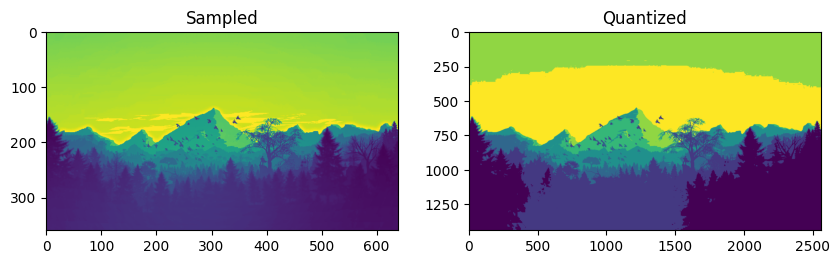

In [2]:
im = cv2.imread('mountains.jpg', 0)

s = 4
sm = im[::s, ::s]

L = 8
q = np.floor(im/(256/L))*(256/L)
q = q.astype(np.uint8)

plt.figure(figsize=(10,4))

plt.subplot(121)
plt.imshow(sm)
plt.title('Sampled')

plt.subplot(122)
plt.imshow(q)
plt.title('Quantized')

plt.show()

## Histogram Analysis

/tmp/ipykernel_63210/1392848005.py:7: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(im.ravel(), 256, [0,256])
/tmp/ipykernel_63210/1392848005.py:11: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(q.ravel(), 256, [0,256])


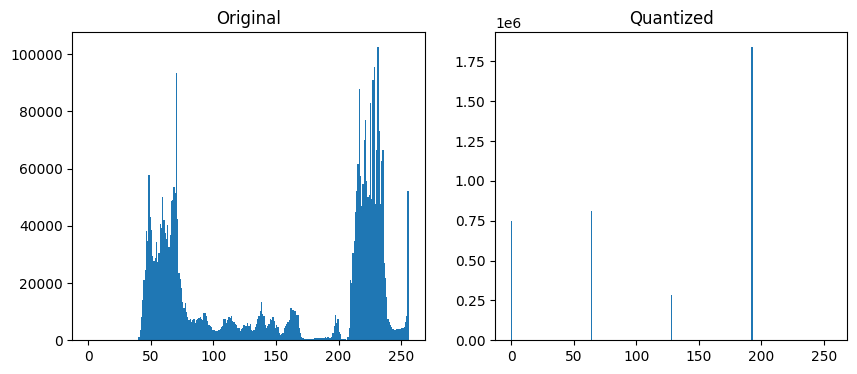

152.80685980902777
119.83409722222223


In [3]:
L = 4
q = (im//(256//L))*(256//L)

plt.figure(figsize=(10,4))

plt.subplot(121)
plt.hist(im.ravel(), 256, [0,256])
plt.title('Original')

plt.subplot(122)
plt.hist(q.ravel(), 256, [0,256])
plt.title('Quantized')

plt.show()

print(im.mean())
print(q.mean())

## 1D FFT

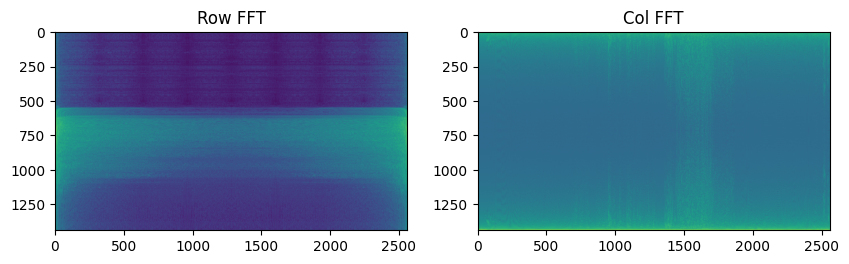

In [4]:
fr = np.fft.fft(im, axis=1)
fc = np.fft.fft(im, axis=0)

plt.figure(figsize=(10,4))

plt.subplot(121)
plt.imshow(np.log(1+np.abs(fr)))
plt.title('Row FFT')

plt.subplot(122)
plt.imshow(np.log(1+np.abs(fc)))
plt.title('Col FFT')

plt.show()

## 2D FFT

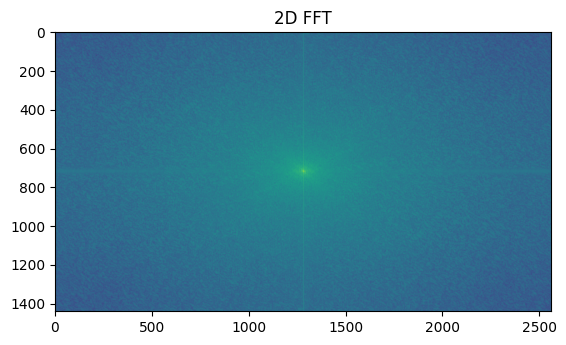

In [5]:
f = np.fft.fft2(im)
fs = np.fft.fftshift(f)

m = np.log(1+np.abs(fs))

plt.imshow(m)
plt.title('2D FFT')
plt.show()

## DCT

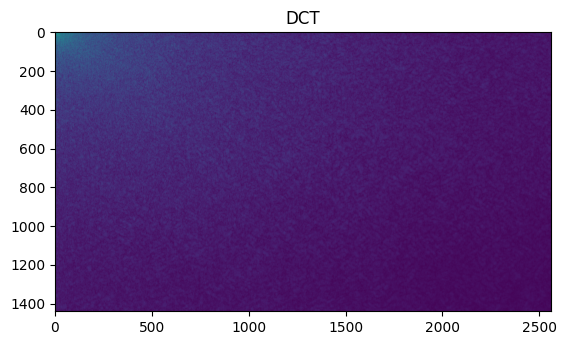

In [6]:
d = cv2.dct(np.float32(im))

s = np.log(abs(d) + 1)

plt.imshow(s)
plt.title('DCT')
plt.show()

## Ideal Low Pass Filter

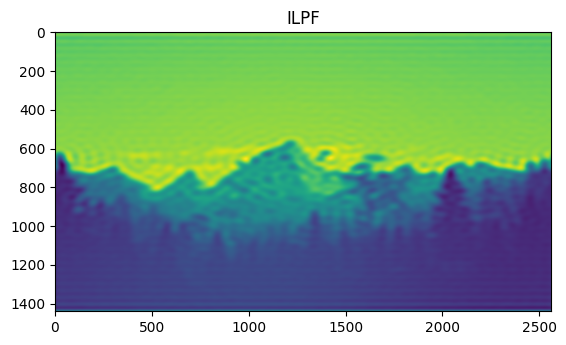

In [7]:
f = np.fft.fftshift(np.fft.fft2(im))

r,c = im.shape
x,y = np.ogrid[:r,:c]

cx,cy = r//2,c//2
d = 40

m = ((x-cx)**2 + (y-cy)**2)<=d*d

g = f*m

o = np.abs(np.fft.ifft2(np.fft.ifftshift(g)))

plt.imshow(o)
plt.title('ILPF')
plt.show()

## Butterworth Low Pass Filter

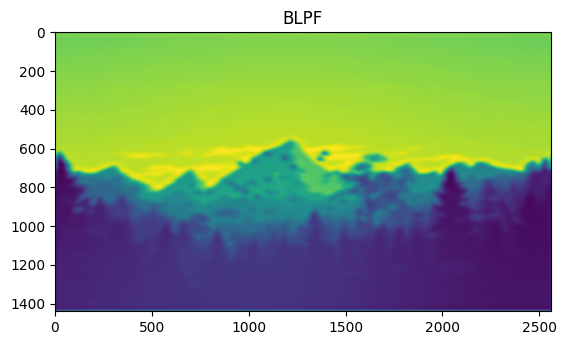

In [8]:
f = np.fft.fftshift(np.fft.fft2(im))

r,c = im.shape
x,y = np.ogrid[:r,:c]

cx,cy = r//2,c//2

D = np.sqrt((x-cx)**2 + (y-cy)**2)

d0 = 40
n = 2

h = 1/(1+(D/d0)**(2*n))

g = f*h

o = np.abs(np.fft.ifft2(np.fft.ifftshift(g)))

plt.imshow(o)
plt.title('BLPF')
plt.show()

## Gaussian Low Pass Filter

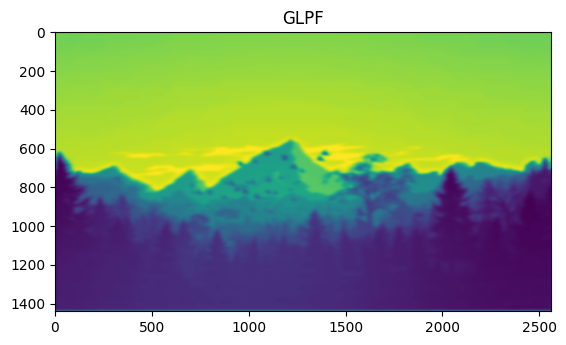

In [9]:
f = np.fft.fftshift(np.fft.fft2(im))

r,c = im.shape
x,y = np.ogrid[:r,:c]

cx,cy = r//2,c//2

d0 = 40

D = (x-cx)**2 + (y-cy)**2

h = np.exp(-D/(2*d0*d0))

g = f*h

o = np.abs(np.fft.ifft2(np.fft.ifftshift(g)))

plt.imshow(o)
plt.title('GLPF')
plt.show()

## Ideal High Pass Filter

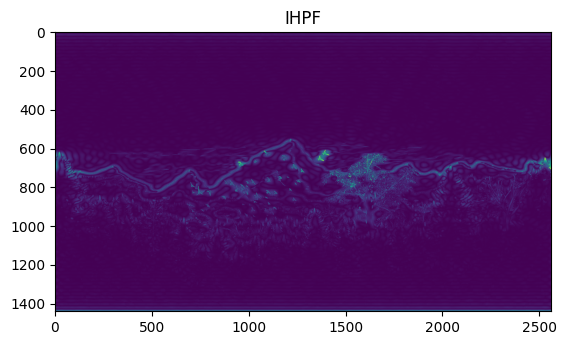

In [10]:
f = np.fft.fftshift(np.fft.fft2(im))

r,c = im.shape
x,y = np.ogrid[:r,:c]

cx,cy = r//2,c//2

d = 40

h = ((x-cx)**2 + (y-cy)**2)>d*d

g = f*h

o = np.abs(np.fft.ifft2(np.fft.ifftshift(g)))

plt.imshow(o)
plt.title('IHPF')
plt.show()

## Butterworth High Pass Filter

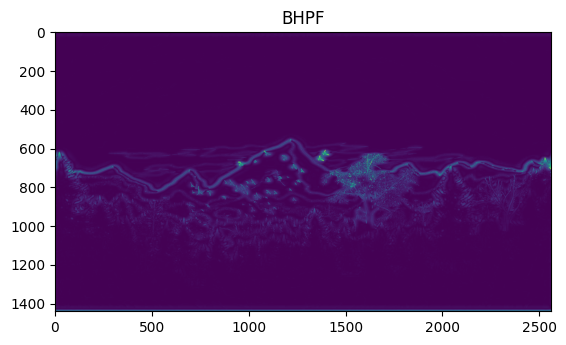

In [11]:
f = np.fft.fftshift(np.fft.fft2(im))

r,c = im.shape
x,y = np.ogrid[:r,:c]

cx,cy = r//2,c//2

D = np.sqrt((x-cx)**2 + (y-cy)**2)

d0 = 40
n = 2

h = 1 - 1/(1+(D/d0)**(2*n))

g = f*h

o = np.abs(np.fft.ifft2(np.fft.ifftshift(g)))

plt.imshow(o)
plt.title('BHPF')
plt.show()

## High Boost Filtering

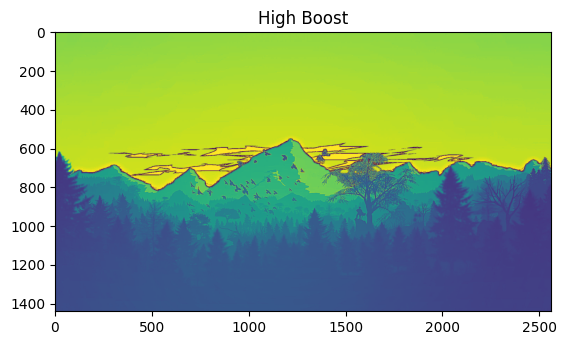

In [12]:
b = cv2.GaussianBlur(im,(11,11),0)

m = im - b

k = 2

o = im + k*m

plt.imshow(o)
plt.title('High Boost')
plt.show()

## Homomorphic Filtering

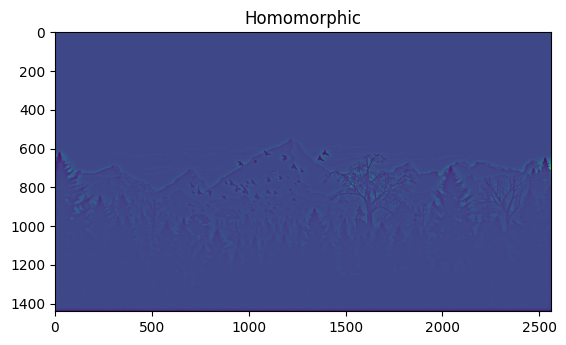

In [13]:
im = np.float32(im)+1

l = np.log(im)

f = np.fft.fftshift(np.fft.fft2(l))

r,c = im.shape
x,y = np.ogrid[:r,:c]

cx,cy = r//2,c//2

D = (x-cx)**2 + (y-cy)**2

h = 1 - np.exp(-D/(2*30*30))

g = f*h

o = np.fft.ifft2(np.fft.ifftshift(g))
o = np.exp(np.real(o))

plt.imshow(o)
plt.title('Homomorphic')
plt.show()